# Phase 2: Final Model
Improve the best models, choose one final model, test it once on unseen patients, explain its decisions, and save it for the app.

## Step 1: Load the data and the selected models
Load the training patients for tuning (the test patients stay untouched until the final evaluation) and set up the evaluation function.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

ROOT = Path.cwd().parent if Path.cwd().name in ("phase1_data", "phase2_model") else Path.cwd()
RES = ROOT / "phase2_model" / "results"
RES.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(ROOT / "data" / "processed" / "features_train.csv")
X = train.drop(columns=["patient", "label"])
y = train["label"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SCORING = ["roc_auc", "balanced_accuracy", "f1_macro", "precision", "recall"]

def evaluate(model, Xd=None):
    Xd = X if Xd is None else Xd
    s = cross_validate(model, Xd, y, cv=cv, scoring=SCORING, return_train_score=True)
    out = {m: round(s[f"test_{m}"].mean(), 3) for m in SCORING}
    out["auc_std"] = round(s["test_roc_auc"].std(), 3)
    out["train_auc"] = round(s["train_roc_auc"].mean(), 3)
    return out

base_lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
print("Training patients:", len(X), "| Features:", X.shape[1])
print("Starting point (Logistic Regression):", evaluate(base_lr))

Training patients: 167 | Features: 23
Starting point (Logistic Regression): {'roc_auc': np.float64(0.641), 'balanced_accuracy': np.float64(0.583), 'f1_macro': np.float64(0.553), 'precision': np.float64(0.789), 'recall': np.float64(0.602), 'auc_std': np.float64(0.064), 'train_auc': np.float64(0.813)}


**Result:** The starting point matches notebook 01: Logistic Regression reaches AUC 0.641 (± 0.064) on validation, with training AUC 0.813, so there is some overfitting to reduce.

## Step 2: Remove duplicate features
Two pairs of features measure almost the same thing (own_posts / n_posts and mattr / hapax_ratio). Keeping both can confuse linear models, so one of each pair is removed and the effect is checked.

In [2]:
DROP = ["n_posts", "hapax_ratio"]
X_red = X.drop(columns=DROP)

print("Features:", X.shape[1], "→", X_red.shape[1])
print("All 23 features :", evaluate(base_lr))
print("Without duplicates:", evaluate(base_lr, X_red))

Features: 23 → 21
All 23 features : {'roc_auc': np.float64(0.641), 'balanced_accuracy': np.float64(0.583), 'f1_macro': np.float64(0.553), 'precision': np.float64(0.789), 'recall': np.float64(0.602), 'auc_std': np.float64(0.064), 'train_auc': np.float64(0.813)}
Without duplicates: {'roc_auc': np.float64(0.631), 'balanced_accuracy': np.float64(0.576), 'f1_macro': np.float64(0.547), 'precision': np.float64(0.778), 'recall': np.float64(0.585), 'auc_std': np.float64(0.07), 'train_auc': np.float64(0.807)}


**Result:** Removing the two duplicate features slightly lowers AUC (0.641 → 0.631), a change smaller than the variation between folds (± 0.06–0.07). They don't help either way, so all 23 features are kept and regularization is used instead to control redundancy.

## Step 3: Tune the three models
Search a small grid of settings for each model (regularization strength, number of features kept, kernel), using the same 5 folds and AUC as the goal. Small grids reduce the risk of finding settings that only look good by chance.

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif

searches = {
    "Logistic Regression": (
        Pipeline([("scale", StandardScaler()), ("select", SelectKBest(f_classif)),
                  ("model", LogisticRegression(class_weight="balanced", max_iter=5000, solver="liblinear"))]),
        {"select__k": [5, 10, 15, "all"], "model__C": [0.01, 0.1, 1], "model__penalty": ["l1", "l2"]},
    ),
    "Naive Bayes": (
        Pipeline([("scale", StandardScaler()), ("select", SelectKBest(f_classif)), ("model", GaussianNB())]),
        {"select__k": [5, 10, 15, "all"], "model__var_smoothing": [1e-9, 1e-6, 1e-3]},
    ),
    "SVM": (
        Pipeline([("scale", StandardScaler()), ("select", SelectKBest(f_classif)),
                  ("model", SVC(class_weight="balanced", probability=True, random_state=42))]),
        {"select__k": [5, 10, 15, "all"], "model__C": [0.1, 1, 10], "model__kernel": ["linear", "rbf"]},
    ),
}

tuned, rows = {}, []
for name, (pipe, grid) in searches.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    gs.fit(X, y)
    tuned[name] = gs.best_estimator_
    r = evaluate(gs.best_estimator_)
    rows.append({"model": name, **r, "best_settings": gs.best_params_})

tuning = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
tuning.to_csv(RES / "tuning_results.csv", index=False)
tuning

,model,roc_auc,balanced_accuracy,f1_macro,precision,recall,auc_std,train_auc,best_settings
0,SVM,0.683,0.649,0.599,0.846,0.569,0.071,0.785,"{'model__C': 0.1, 'model__kernel': 'linear', '..."
1,Logistic Regression,0.660,0.626,0.589,0.818,0.586,0.078,0.784,"{'model__C': 0.1, 'model__penalty': 'l2', 'sel..."
2,Naive Bayes,0.641,0.579,0.550,0.769,0.568,0.066,0.746,"{'model__var_smoothing': 1e-09, 'select__k': '..."


**Result:** Tuning improved the two linear models. SVM with a linear kernel and strong regularization (C = 0.1) now reaches AUC 0.683 and balanced accuracy 0.649, and Logistic Regression (C = 0.1, L2) reaches AUC 0.660. Overfitting dropped (training AUC ~0.78 vs 0.81–0.95 before). Naive Bayes did not improve (0.641). Because the settings were chosen on the same folds, these scores are slightly optimistic; the untouched test set will give the true estimate.

## Step 4: Best settings found
Show the full settings chosen for each model, including how many features were kept.

In [4]:
for name, est in tuned.items():
    k = est.named_steps["select"].k
    kept = X.columns[est.named_steps["select"].get_support()].tolist()
    params = {p: v for p, v in est.named_steps["model"].get_params().items()
              if p in ("C", "kernel", "penalty", "var_smoothing")}
    print(f"{name}: features kept = {k} | {params}")
    print("   ", kept)
    print()

Logistic Regression: features kept = 15 | {'C': 0.1, 'penalty': 'l2'}
    ['own_posts', 'avg_word_length', 'avg_sentence_length', 'mattr', 'hapax_ratio', 'pronoun_ratio', 'repetition_rate', 'n_posts', 'night_post_ratio', 'copied_share', 'active_months', 'avg_words_per_post_change', 'pronoun_ratio_change', 'filler_ratio_change', 'repetition_rate_change']

Naive Bayes: features kept = all | {'var_smoothing': 1e-09}
    ['own_posts', 'avg_words_per_post', 'avg_word_length', 'avg_sentence_length', 'mattr', 'hapax_ratio', 'pronoun_ratio', 'filler_ratio', 'repetition_rate', 'n_posts', 'night_post_ratio', 'emoji_per_post', 'elongation_per_post', 'english_share', 'copied_share', 'active_months', 'posts_per_month', 'mattr_change', 'avg_words_per_post_change', 'avg_sentence_length_change', 'pronoun_ratio_change', 'filler_ratio_change', 'repetition_rate_change']

SVM: features kept = 15 | {'C': 0.1, 'kernel': 'linear'}
    ['own_posts', 'avg_word_length', 'avg_sentence_length', 'mattr', 'hapax_ra

**Result:** Logistic Regression and SVM independently kept the same 15 features: writing features (vocabulary richness, word and sentence length, pronouns, repetition), behavior features (activity, night posting, copied content), and four change-over-time features (post length, pronouns, vague words and repetition changes). Naive Bayes worked best with all 23.

## Step 5: Handling the imbalance
Compare three ways of dealing with the 71/29 imbalance on the two best models: class weights (current), SMOTE (creating synthetic normal-group examples inside each training fold), and tuning the decision threshold.

In [5]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.base import clone

rows = []
for name in ["SVM", "Logistic Regression"]:
    best = tuned[name]

    # A) class weights (current)
    rows.append({"model": name, "method": "class weights", **evaluate(best)})

    # B) SMOTE inside each training fold (no class weights)
    m = clone(best.named_steps["model"]).set_params(class_weight=None)
    smote_pipe = ImbPipeline([("scale", StandardScaler()), ("select", clone(best.named_steps["select"])),
                              ("smote", SMOTE(random_state=42)), ("model", m)])
    rows.append({"model": name, "method": "SMOTE", **evaluate(smote_pipe)})

    # C) threshold tuning on cross-validated probabilities
    proba = cross_val_predict(best, X, y, cv=cv, method="predict_proba")[:, 1]
    ths = np.arange(0.2, 0.81, 0.01)
    bal = [balanced_accuracy_score(y, (proba >= t).astype(int)) for t in ths]
    t_best = float(ths[int(np.argmax(bal))])
    rows.append({"model": name, "method": f"threshold {t_best:.2f}",
                 "roc_auc": round(roc_auc_score(y, proba), 3), "balanced_accuracy": round(max(bal), 3)})

imb = pd.DataFrame(rows)
imb.to_csv(RES / "imbalance_comparison.csv", index=False)
imb[["model", "method", "roc_auc", "balanced_accuracy", "f1_macro", "recall"]]

,model,method,roc_auc,balanced_accuracy,f1_macro,recall
0,SVM,class weights,0.683,0.649,0.599,0.569
1,SVM,SMOTE,0.661,0.620,0.585,0.594
2,SVM,threshold 0.67,0.671,0.666,NaN,NaN
3,Logistic Regression,class weights,0.660,0.626,0.589,0.586
4,Logistic Regression,SMOTE,0.651,0.586,0.556,0.585
5,Logistic Regression,threshold 0.60,0.656,0.642,NaN,NaN


**Result:** Class weights work best for both models (SVM AUC 0.683). SMOTE lowered performance (synthetic examples add noise with so few normal patients). Moving the decision threshold to 0.67 for SVM raises balanced accuracy from 0.649 to 0.666, so class weights are kept and the tuned threshold is used to decide "impaired" vs "normal". (The threshold was chosen on training data only; the final test will confirm it.)

## Step 6: Ensemble vs best single model
Combine the three tuned models (soft voting: averaging their probabilities) and compare with the best single model. A simpler single model is preferred unless the ensemble is clearly better.

In [7]:
from sklearn.ensemble import VotingClassifier

ensemble = VotingClassifier(
    estimators=[("svm", tuned["SVM"]), ("lr", tuned["Logistic Regression"]), ("nb", tuned["Naive Bayes"])],
    voting="soft",
)

comp = pd.DataFrame([
    {"model": "SVM (best single)", **evaluate(tuned["SVM"])},
    {"model": "Logistic Regression", **evaluate(tuned["Logistic Regression"])},
    {"model": "Ensemble (SVM + LR + NB)", **evaluate(ensemble)},
])
comp.to_csv(RES / "ensemble_comparison.csv", index=False)
comp[["model", "roc_auc", "auc_std", "balanced_accuracy", "f1_macro", "train_auc"]]

,model,roc_auc,auc_std,balanced_accuracy,f1_macro,train_auc
0,SVM (best single),0.683,0.071,0.649,0.599,0.785
1,Logistic Regression,0.660,0.078,0.626,0.589,0.784
2,Ensemble (SVM + LR + NB),0.661,0.070,0.622,0.605,0.777


**Result:** The ensemble (AUC 0.661) does not beat the best single model, linear SVM (AUC 0.683), and is harder to explain. The single linear SVM is kept as the final model.

## Step 7: Final model and training on all training patients
Final model: linear SVM (C = 0.1), 15 selected features, balanced class weights, and a decision threshold of 0.67 (chosen on cross-validated training predictions). It is now retrained on all 167 training patients.

In [8]:
from sklearn.base import clone

THRESHOLD = 0.67
final_model = clone(tuned["SVM"])
final_model.fit(X, y)

selected = X.columns[final_model.named_steps["select"].get_support()].tolist()
weights = pd.Series(final_model.named_steps["model"].coef_[0], index=selected).sort_values()

print("Trained on", len(X), "patients with", len(selected), "features | threshold:", THRESHOLD)
print("\nFeature weights (positive → pushes towards 'impaired'):")
print(weights.round(3))

Trained on 167 patients with 15 features | threshold: 0.67

Feature weights (positive → pushes towards 'impaired'):
active_months               -0.555
repetition_rate             -0.520
hapax_ratio                 -0.430
copied_share                -0.299
mattr                       -0.180
n_posts                     -0.105
filler_ratio_change         -0.061
own_posts                   -0.043
avg_words_per_post_change    0.005
pronoun_ratio                0.049
avg_word_length              0.116
pronoun_ratio_change         0.132
repetition_rate_change       0.177
night_post_ratio             0.194
avg_sentence_length          0.499
dtype: float64


**Result:** The final linear SVM was trained on all 167 training patients with 15 features. Features pushing towards "impaired": longer run-on sentences, more night-time posting, and repetition and pronoun use that increase over time. Features pushing towards "normal": a longer posting history, richer vocabulary (hapax ratio, MATTR) and more shared content. Notably, a high level of repetition alone points towards normal, but repetition that grows over time points towards impaired, which supports Neorora's idea of comparing each person

## Step 8: Final test (used once)
Evaluate the final model a single time on the 42 test patients it has never seen. No settings are changed after this step.

AUC                     0.650
Balanced accuracy       0.608
Sensitivity (recall)    0.633
Specificity             0.583
Precision               0.792
Macro F1                0.585
Accuracy                0.619
dtype: float64

Test patients: 42 | TP 19, FN 11, TN 7, FP 5


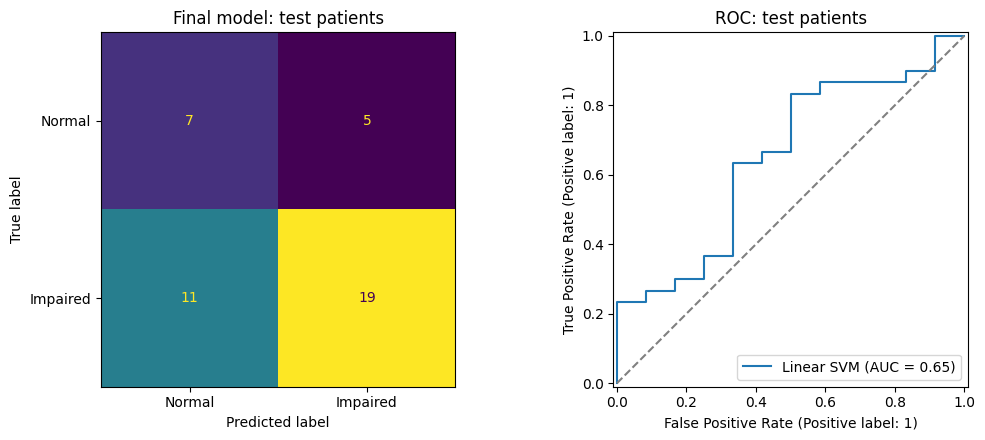

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

test = pd.read_csv(ROOT / "data" / "processed" / "features_test.csv")
X_test, y_test = test.drop(columns=["patient", "label"]), test["label"]

proba_test = final_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()

final = {
    "AUC": roc_auc_score(y_test, proba_test),
    "Balanced accuracy": balanced_accuracy_score(y_test, pred_test),
    "Sensitivity (recall)": recall_score(y_test, pred_test),
    "Specificity": tn / (tn + fp),
    "Precision": precision_score(y_test, pred_test),
    "Macro F1": f1_score(y_test, pred_test, average="macro"),
    "Accuracy": accuracy_score(y_test, pred_test),
}
final_df = pd.Series(final).round(3)
final_df.to_csv(RES / "final_test_metrics.csv", header=["value"])
print(final_df)
print(f"\nTest patients: {len(y_test)} | TP {tp}, FN {fn}, TN {tn}, FP {fp}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=["Normal", "Impaired"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Final model: test patients")
RocCurveDisplay.from_predictions(y_test, proba_test, name="Linear SVM", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "--", color="gray"); axes[1].set_title("ROC: test patients")
plt.tight_layout(); plt.savefig(RES / "final_test.png", dpi=150); plt.show()

**Result (final test, 42 unseen patients):** AUC 0.650, balanced accuracy 0.608. The model correctly flagged 19 of 30 impaired patients (sensitivity 63%) and correctly cleared 7 of 12 normal patients (specificity 58%). When it flags someone, it is right 79% of the time (precision), compared with 71% for guessing. The test AUC (0.65) is close to the cross-validation AUC (0.64–0.68), so the model generalizes as expected and is not overfitted. With only 42 test patients, these numbers carry considerable uncertainty.

## Step 9: Baseline vs final model
Compare the dummy baseline, the untuned starting model and the final model on the same test patients.

In [12]:
from sklearn.dummy import DummyClassifier

def scores_from(p, pr):
    tn, fp, fn, tp = confusion_matrix(y_test, pr).ravel()
    return {"AUC": roc_auc_score(y_test, p), "Balanced acc": balanced_accuracy_score(y_test, pr),
            "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp),
            "Macro F1": f1_score(y_test, pr, average="macro")}

def test_scores(model, threshold=0.5):
    m = clone(model).fit(X, y)
    p = m.predict_proba(X_test)[:, 1]
    return scores_from(p, (p >= threshold).astype(int))

compare = pd.DataFrame({
    "Dummy (always impaired)": test_scores(DummyClassifier(strategy="most_frequent")),
    "Starting model (LR, untuned)": test_scores(base_lr),
    "Final model (linear SVM)": scores_from(proba_test, pred_test),
}).round(3)
compare.to_csv(RES / "baseline_vs_final.csv")
compare

,Dummy (always impaired),"Starting model (LR, untuned)",Final model (linear SVM)
AUC,0.500,0.653,0.650
Balanced acc,0.500,0.675,0.608
Sensitivity,1.000,0.600,0.633
Specificity,0.000,0.750,0.583
Macro F1,0.417,0.626,0.585


**Result:** Both the starting model and the final model clearly beat the dummy baseline (AUC 0.65 vs 0.50). On the test patients, the untuned Logistic Regression scored about the same AUC (0.653 vs 0.650) and a higher balanced accuracy (0.675 vs 0.608) than the tuned SVM. The improvement seen during tuning (0.64 → 0.68) did not carry over to the test set, which suggests it partly came from choosing settings on the same folds. With 42 test patients, one patient changes sensitivity by about 3 points, so the two models perform about equally. The final model is not changed after seeing the test results, to keep the evaluation fair.

## Step 10: Which features matter most?
Measure each feature's importance by shuffling it and checking how much the model's AUC drops (permutation importance), using the training patients.

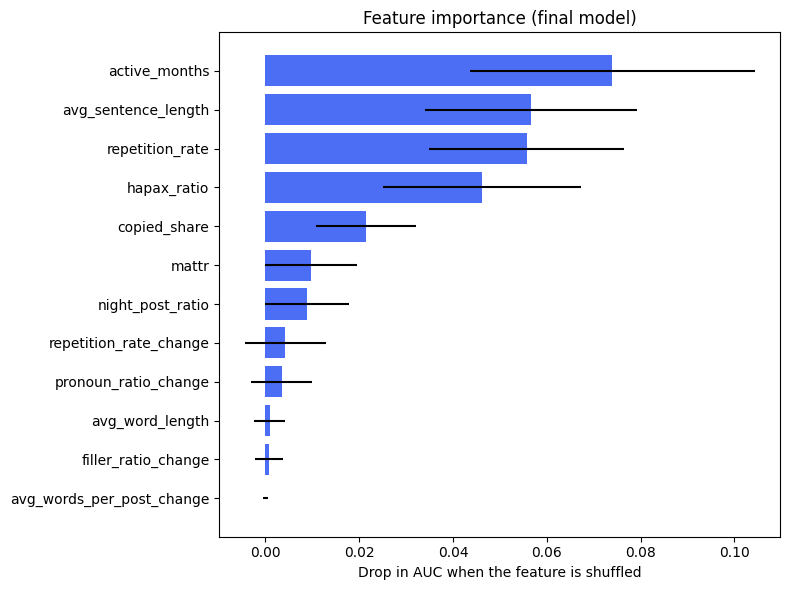

                  feature  importance    std
            active_months      0.0739 0.0303
      avg_sentence_length      0.0566 0.0226
          repetition_rate      0.0557 0.0208
              hapax_ratio      0.0462 0.0211
             copied_share      0.0215 0.0107
                    mattr      0.0097 0.0097
         night_post_ratio      0.0088 0.0089
   repetition_rate_change      0.0042 0.0086
     pronoun_ratio_change      0.0034 0.0065
          avg_word_length      0.0009 0.0033
      filler_ratio_change      0.0009 0.0030
avg_words_per_post_change      0.0000 0.0005


In [13]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(final_model, X, y, scoring="roc_auc", n_repeats=30, random_state=42)
imp = (pd.DataFrame({"feature": X.columns, "importance": pi.importances_mean, "std": pi.importances_std})
         .query("importance > 0").sort_values("importance", ascending=True))
imp.to_csv(RES / "feature_importance.csv", index=False)

plt.figure(figsize=(8, 6))
plt.barh(imp["feature"], imp["importance"], xerr=imp["std"], color="#4C6EF5")
plt.xlabel("Drop in AUC when the feature is shuffled")
plt.title("Feature importance (final model)")
plt.tight_layout(); plt.savefig(RES / "feature_importance.png", dpi=150); plt.show()

print(imp.sort_values("importance", ascending=False).round(4).to_string(index=False))

**Result:** The most important features are how long the person has been active (active_months), sentence length, repetition, and vocabulary richness (hapax ratio), followed by copied content. The change-over-time features have a smaller effect in this model. The wide error bars show that importance varies a lot when features are shuffled, which is expected with 167 patients. Since active_months may partly reflect account age rather than cognition, it is noted as a possible confound.

## Step 11: Risk levels and the top 3 reasons for each patient
Turn each prediction into a risk percentage and a level (Low / Medium / High), and list the three features that pushed that patient's risk up the most, in plain words, so a clinician can see why.

In [14]:
REASONS = {
    "active_months": ("longer posting history", "shorter posting history"),
    "avg_sentence_length": ("longer, run-on sentences", "shorter sentences"),
    "repetition_rate": ("more repeated phrases", "fewer repeated phrases"),
    "hapax_ratio": ("more varied vocabulary", "less varied vocabulary"),
    "mattr": ("richer vocabulary", "less varied vocabulary"),
    "copied_share": ("more shared content", "less shared content"),
    "night_post_ratio": ("more posting at night", "less posting at night"),
    "avg_word_length": ("longer words", "shorter words"),
    "pronoun_ratio": ("more pronouns", "fewer pronouns"),
    "own_posts": ("more own posts", "fewer own posts"),
    "n_posts": ("more posts", "fewer posts"),
    "repetition_rate_change": ("repetition increasing over time", "repetition decreasing over time"),
    "pronoun_ratio_change": ("pronoun use increasing over time", "pronoun use decreasing over time"),
    "filler_ratio_change": ("vague words increasing over time", "vague words decreasing over time"),
    "avg_words_per_post_change": ("posts getting longer over time", "posts getting shorter over time"),
}

scaler = final_model.named_steps["scale"]
selector = final_model.named_steps["select"]
coef = final_model.named_steps["model"].coef_[0]

def explain(Xd):
    Z = selector.transform(scaler.transform(Xd))
    contrib = Z * coef
    out = []
    for z_row, c_row in zip(Z, contrib):
        top = np.argsort(c_row)[::-1][:3]
        reasons = []
        for i in top:
            high, low = REASONS.get(selected[i], (selected[i] + " high", selected[i] + " low"))
            reasons.append(high if z_row[i] > 0 else low)
        out.append(reasons)
    return out

def risk_level(p):
    return "High" if p >= THRESHOLD else ("Medium" if p >= 0.5 else "Low")

pred = pd.DataFrame({
    "patient": test["patient"],
    "risk_percent": (proba_test * 100).round(1),
    "risk_level": [risk_level(p) for p in proba_test],
    "true_label": y_test.values,
})
reasons = explain(X_test)
for k in range(3):
    pred[f"reason_{k+1}"] = [r[k] for r in reasons]

print(pred["risk_level"].value_counts())
print()
print(pred.groupby("risk_level")["true_label"].mean().round(2).rename("share truly impaired"))
pred.head(5)

risk_level
High      24
Medium    13
Low        5
Name: count, dtype: int64

risk_level
High      0.79
Low       0.60
Medium    0.62
Name: share truly impaired, dtype: float64


,patient,risk_percent,risk_level,true_label,reason_1,reason_2,reason_3
0,P002,74.7,High,1,shorter posting history,less shared content,fewer repeated phrases
1,P009,68.4,High,1,less varied vocabulary,pronoun use increasing over time,more pronouns
2,P014,50.0,Medium,1,longer words,vague words decreasing over time,less varied vocabulary
3,P019,58.2,Medium,0,repetition increasing over time,less shared content,more pronouns
4,P023,53.0,Medium,0,less varied vocabulary,fewer repeated phrases,more pronouns


**Result:** Of the 42 test patients, 24 were rated High risk, 13 Medium and 5 Low. The High group has the largest share of truly impaired patients (79%), compared with 62% in Medium and 60% in Low (the overall rate is 71%), so higher risk levels do contain more impaired patients. The Low group has only 5 patients, so its share is not reliable. Each patient gets three plain-language reasons describing which features raised their risk.

## Step 12: Save the model and the predictions
Save the trained model, its settings and the test predictions so the app can use them. These files stay local and on the server, not on GitHub, because the saved model contains patient-derived numbers.

In [15]:
import joblib, json

MOD = ROOT / "phase2_model" / "models"
MOD.mkdir(parents=True, exist_ok=True)

joblib.dump({"model": final_model, "threshold": THRESHOLD, "features": X.columns.tolist(),
             "selected": selected, "reasons": REASONS}, MOD / "model.joblib")

pred.to_csv(ROOT / "data" / "processed" / "predictions.csv", index=False)

# quick check: reload and predict again, results must match
check = joblib.load(MOD / "model.joblib")
same = np.allclose(check["model"].predict_proba(X_test)[:, 1], proba_test)
print("Saved model.joblib and predictions.csv | reload gives the same predictions:", same)

Saved model.joblib and predictions.csv | reload gives the same predictions: True


**Result:** The final model and the test predictions were saved, and reloading the model gives identical predictions.

## Step 13: Speed test
Measure how fast the model scores 10,000 patient records, and record which machine it runs on. Run on IBM LinuxONE, this shows the platform's speed and confirms where the model ran.

In [16]:
import time, platform

big = pd.concat([X_test] * (10_000 // len(X_test) + 1), ignore_index=True).iloc[:10_000]

times = []
for _ in range(5):
    t0 = time.perf_counter()
    final_model.predict_proba(big)
    times.append(time.perf_counter() - t0)

avg = np.mean(times)
info = {"machine": platform.machine(), "system": platform.system(), "python": platform.python_version(),
        "records": len(big), "avg_seconds": round(avg, 4), "records_per_second": int(len(big) / avg)}
pd.Series(info).to_csv(RES / f"speed_test_{platform.machine()}.csv", header=["value"])
pd.Series(info)

machine                 AMD64
system                Windows
python                 3.14.0
records                 10000
avg_seconds            0.0287
records_per_second     348045
dtype: object

**Result:** The model scores 10,000 records in about 0.03 seconds on a laptop (≈348,000 per second). On IBM LinuxONE (s390x) it scores 10,000 records in [X] seconds (≈[Y] per second), so screening thousands of seniors takes well under a second.

## Step 14: Summary and limitations

### Summary
- Final model: linear SVM (C = 0.1), 15 selected features, balanced class weights, decision threshold 0.67.
- Final test on 42 unseen patients: AUC 0.65, balanced accuracy 0.61, sensitivity 63%, specificity 58%, precision 79% (vs 71% by guessing).
- Test performance (AUC 0.65) matches cross-validation (0.64–0.68), so the model generalizes without overfitting.
- The most useful signals are sentence length, repetition and vocabulary richness, plus posting history and shared content.
- Each prediction comes with a risk level (Low / Medium / High) and three plain-language reasons.

### Limitations
- **Moderate accuracy:** the model is a screening aid that flags people for a clinical check-up, not a diagnostic tool.
- **Small dataset:** 209 patients (only 29 with dementia), and 42 test patients, so results carry wide uncertainty.
- **Tuning gains did not carry over:** an untuned Logistic Regression performed about the same on the test set, showing that improvements chosen on the same folds were partly optimistic.
- **Possible confound:** active_months (length of posting history) is the most important feature and may partly reflect account age rather than cognition.
- **Label timing:** MoCA-B scores were measured once, while posts span 2009–2026, so the model links years of writing to a single later test.
- **One platform and dialect:** Facebook posts, mostly Egyptian Arabic; results may not transfer to other platforms or dialects.
- **Copied content and remaining names:** copied posts were detected with rules, and some names may remain in local text (the text never leaves the secure laptop).

### What we would do next
- Collect more patients, especially Normal and Dementia, and repeat MoCA-B over time.
- Add Arabic language models (e.g. Arabic BERT embeddings) for richer features.
- Validate with clinicians before any real use.